# PlantVillage: Kiểm Thử Độc Lập & So Sánh Mô Hình Đa Định Dạng (.keras, .h5, .pth)

**Dự án:** Phân loại bệnh hại trên lá cây trồng (Plant Disease Classification)  
**Mục tiêu Notebook:**
1. Hỗ trợ nạp và kiểm thử linh hoạt các mô hình từ nhiều framework & định dạng khác nhau: **`.keras`** (Keras 3 / TensorFlow), **`.h5`** (Keras Legacy HDF5), và **`.pth` / `.pt`** (PyTorch).
2. So sánh đối chuẩn toàn diện: Số lượng dự đoán đúng ($N_{\text{correct}}$), số lượng dự đoán sai ($N_{\text{wrong}}$), tỷ lệ chính xác (Accuracy %), tỷ lệ lỗi (Error Rate %), Macro/Weighted F1-score và độ trễ suy luận (latency ms/ảnh).
3. **Trực quan hóa chẩn đoán 9 ảnh (3x3 grid):** Hiển thị chi tiết ảnh lá cây, nhãn thực tế (Ground Truth), kết quả phân loại của từng mô hình, độ tin cậy (%) và tổng kết số lượng / tỷ lệ đúng-sai cụ thể trên 9 ảnh.
4. Phân tích chi tiết các mẫu bị nhận diện sai (Misclassified Analysis) và chẩn đoán ảnh đơn lẻ bất kỳ.

---


## 1. Khởi Tạo Môi Trường & Thiết Lập Cấu Hình

Khai báo các thư viện phụ thuộc, cấu hình khử xung đột OpenMP trên hệ điều hành Windows (`KMP_DUPLICATE_LIB_OK`), tắt cảnh báo rác của TensorFlow và nhận diện thiết bị tính toán phần cứng (GPU/CPU).


In [1]:
import os
import sys
from pathlib import Path

# 1. Tránh xung đột Intel OpenMP khi nạp đồng thời PyTorch và TensorFlow trên Windows
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

# 2. Thêm thư mục gốc của dự án vào sys.path
current_dir = Path('.').resolve()
if (current_dir / 'plantvillage_dataset').exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'plantvillage_dataset').exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:


import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import torch
import importlib

# 3. Tự động nạp lại module nếu kernel Jupyter chưa khởi động lại
for mod_name in ['src.evaluation.model_comparator', 'src.evaluation', 'src']:
    if mod_name in sys.modules:
        try:
            importlib.reload(sys.modules[mod_name])
        except Exception:
            pass

from src.evaluation.model_comparator import (
    load_universal_model,
    compare_multiple_models,
    visualize_9_predictions,
    plot_model_comparison_charts,
    UniversalModelWrapper,
)

# Kích hoạt tương thích ngược nạp các mô hình .h5 cũ (Keras 2)
try:
    from src.evaluation.model_comparator import enable_legacy_keras2_compatibility
    enable_legacy_keras2_compatibility()
except ImportError:
    pass

print(f'[OK] TensorFlow Version: {tf.__version__}')
print(f'[OK] PyTorch Version   : {torch.__version__}')
print(f'[OK] CUDA Available (PyTorch)   : {torch.cuda.is_available()}')
print(f'[OK] GPU Available (TensorFlow) : {len(tf.config.list_physical_devices("GPU")) > 0}')


[OK] TensorFlow Version: 2.20.0
[OK] PyTorch Version   : 2.5.1+cu121
[OK] CUDA Available (PyTorch)   : True
[OK] GPU Available (TensorFlow) : False


## 2. Nạp Ánh Xạ Nhãn (38 Lớp) & Tập Dữ Liệu Kiểm Thử (Test Set)

Tập dữ liệu kiểm thử độc lập bao gồm **8.143 ảnh (15%)** được phân chia bằng phương pháp phân tầng (Stratified Split). Chúng ta sẽ nạp danh sách ảnh và ánh xạ 38 nhãn phân loại từ file cấu hình.


In [ ]:
# Nạp bảng ánh xạ 38 nhãn phân loại
class_indices_path = PROJECT_ROOT / 'outputs/vgg16/reports/class_indices.json'
if class_indices_path.exists():
    with open(class_indices_path, 'r', encoding='utf-8') as f:
        c_map = json.load(f)
        if all(str(k).isdigit() for k in c_map.keys()):
            idx_to_class = {int(k): v for k, v in c_map.items()}
        else:
            idx_to_class = {int(v): k for k, v in c_map.items()}
        class_names = [idx_to_class[i] for i in range(len(idx_to_class))]
else:
    # Fallback từ thư mục phân loại
    class_names = [f'Class_{i}' for i in range(38)]

print(f'Tổng số lớp bệnh cây trồng: {len(class_names)}')
print('5 lớp mẫu đầu tiên:', class_names[:5])

# Đọc tệp test.csv
test_csv_path = PROJECT_ROOT / 'plantvillage_dataset/csv/test.csv'
test_df = pd.read_csv(test_csv_path)
print(f'Tổng số mẫu kiểm thử trong test.csv: {len(test_df):,} ảnh')

# Hàm nạp batch ảnh kiểm thử để đánh giá tương tác nhanh
def load_test_sample_images(df, n_samples=200, random_seed=42):
    sample_df = df.sample(n=n_samples, random_state=random_seed) if n_samples else df
    imgs = []
    lbls = []
    for _, row in sample_df.iterrows():
        p = str(row['path'])
        if not os.path.isabs(p):
            p = str(PROJECT_ROOT / p)
        img = Image.open(p).convert('RGB').resize((224, 224))
        imgs.append(np.array(img, dtype=np.float32))
        lbls.append(int(row['label']))
    return np.array(imgs), np.array(lbls), sample_df

# Nạp sẵn 200 ảnh mẫu ngẫu nhiên phân tầng để suy luận tương tác nhanh (hoặc set n_samples=None để chạy full 8,143 ảnh)
TEST_SAMPLE_SIZE = len(test_df)
test_images, test_labels, sample_test_df = load_test_sample_images(test_df, n_samples=TEST_SAMPLE_SIZE)
print(f'Đã nạp {len(test_images)} ảnh kiểm thử ({test_images.shape}) phục vụ đối chuẩn.')


Tổng số lớp bệnh cây trồng: 38
5 lớp mẫu đầu tiên: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']
Tổng số mẫu kiểm thử trong test.csv: 8,143 ảnh
Đã nạp 8143 ảnh kiểm thử ((8143, 224, 224, 3)) phục vụ đối chuẩn.


## 3. Khám Phá & Chọn Danh Sách Các Mô Hình Đối Chuẩn (.keras, .h5, .pth)

Hệ thống tự động quét toàn bộ các tệp checkpoint trong thư mục `outputs/vgg16/checkpoints/` (hỗ trợ cả `.keras`, `.h5`, `.pth`, `.pt`).

**Bạn có 2 cách chọn danh sách mô hình cần nạp:**
1. **Cách 1 (Tương tác trực quan):** Tích chọn trực tiếp các ô checkbox bên dưới.
2. **Cách 2 (Mã lệnh nhanh):** Thay đổi biến `SELECTED_MODEL_INDICES` (ví dụ: `[1, 2, 3]` hoặc `'all'`).


In [4]:
import ipywidgets as widgets
from IPython.display import display

ckpt_dirs = [
    PROJECT_ROOT / 'models'
]

# 1. Tự động phát hiện toàn bộ các tệp mô hình trong các thư mục checkpoints
discovered_files = []
for d in ckpt_dirs:
    if d.exists():
        discovered_files.extend(
            list(d.glob('*.keras')) + 
            list(d.glob('*.h5')) + 
            list(d.glob('*.pth')) + 
            list(d.glob('*.pt'))
        )
# Loại bỏ trùng lặp và sắp xếp theo thời gian sửa đổi gần nhất
discovered_files = sorted(list(set(discovered_files)), key=lambda p: p.stat().st_mtime, reverse=True)

print(f'Tìm thấy {len(discovered_files)} mô hình trong các thư mục checkpoints:\n')

# 2. Cấu hình mặc định các mô hình ưu tiên chọn (hoặc đặt 'all' để chọn tất cả)
# Bạn có thể sửa danh sách số thứ tự tại đây: ví dụ [1, 2, 3] hoặc [1, 4]
SELECTED_MODEL_INDICES = 'all' # Đổi thành 'all' nếu muốn nạp toàn bộ

# 3. Tạo giao diện Checkbox trực quan với ipywidgets
model_checkboxes = {}
print('DANH SÁCH MÔ HÌNH HIỆN CÓ:')
for i, fpath in enumerate(discovered_files, 1):
    size_mb = fpath.stat().st_size / (1024 * 1024)
    is_default = (SELECTED_MODEL_INDICES == 'all') or (i in SELECTED_MODEL_INDICES) or ('best' in fpath.name) or ('baseline' in fpath.name)
    cb = widgets.Checkbox(
        value=is_default,
        description=f'[{i}] {fpath.name:<40} ({size_mb:>5.1f} MB) [{fpath.suffix}]',
        layout=widgets.Layout(width='auto')
    )
    model_checkboxes[fpath] = cb
    print(f'  [{i}] {fpath.name:<42} | Dung lượng: {size_mb:>6.1f} MB | Định dạng: {fpath.suffix}')


Tìm thấy 2 mô hình trong các thư mục checkpoints:

DANH SÁCH MÔ HÌNH HIỆN CÓ:
  [1] resnet50_best.h5                           | Dung lượng:   91.3 MB | Định dạng: .h5
  [2] vgg16_model.keras                          | Dung lượng:  110.5 MB | Định dạng: .keras


In [5]:
print('\n-> Hãy tích/bỏ tích các ô chọn dưới đây để chọn mô hình muốn đối chuẩn:')
ui_box = widgets.VBox([
    widgets.HTML('<b>Bảng chọn mô hình đối chuẩn (Tick để chọn / Bỏ tick để loại trừ):</b>'),
    *model_checkboxes.values()
])
display(ui_box)



-> Hãy tích/bỏ tích các ô chọn dưới đây để chọn mô hình muốn đối chuẩn:


In [6]:
# Thu thập danh sách tệp được chọn (ưu tiên lấy từ checkbox UI nếu có tương tác)
selected_paths = [fpath for fpath, cb in model_checkboxes.items() if cb.value]

# Fallback theo SELECTED_MODEL_INDICES nếu checkbox không có mục nào được tick
if not selected_paths:
    if SELECTED_MODEL_INDICES == 'all':
        selected_paths = discovered_files
    else:
        selected_paths = [discovered_files[i - 1] for i in SELECTED_MODEL_INDICES if 1 <= i <= len(discovered_files)]

print(f'Bắt đầu nạp {len(selected_paths)} mô hình đã chọn...\n')
loaded_models = []

for p in selected_paths:
    try:
        # Đặt tên hiển thị ngắn gọn kèm đuôi định dạng
        display_name = f'{p.stem} ({p.suffix})'
        wrapper = load_universal_model(
            model_path=str(p),
            model_name=display_name,
            class_names=class_names,
            num_classes=len(class_names),
        )
        loaded_models.append(wrapper)
        print(f'[+] Nạp thành công: {wrapper.name:<35} | Định dạng: {p.suffix:<7} | Framework: {wrapper.framework:<10} | Params: {wrapper.param_count:>11,} | Dung lượng: {wrapper.file_size_mb:>6.1f} MB')
    except Exception as e:
        print(f'[!] Lỗi khi nạp {p.name}: {e}')

print(f'\nTổng số mô hình đã sẵn sàng đối chuẩn: {len(loaded_models)} mô hình.')


Bắt đầu nạp 2 mô hình đã chọn...

[+] Nạp thành công: resnet50_best (.h5)                 | Định dạng: .h5     | Framework: tensorflow | Params:  23,665,586 | Dung lượng:   91.3 MB
[+] Nạp thành công: vgg16_model (.keras)                | Định dạng: .keras  | Framework: tensorflow | Params:  14,734,182 | Dung lượng:  110.5 MB

Tổng số mô hình đã sẵn sàng đối chuẩn: 2 mô hình.


## 4. Thực Hiện Đánh Giá Định Lượng & Bảng So Sánh Chi Tiết

Chạy suy luận đồng thời trên tập mẫu kiểm thử để đo lường:
- **Số lượng mẫu dự đoán đúng** ($N_{\text{correct}}$) và **Tỷ lệ chính xác (Accuracy %)**.
- **Số lượng mẫu dự đoán sai** ($N_{\text{wrong}}$) và **Tỷ lệ lỗi (Error Rate %)**.
- **Macro F1-Score:** Trung bình điều hòa cân bằng giữa các lớp.
- **Inference Latency:** Thời gian xử lý trung bình mỗi ảnh (mili-giây).
- **Số lượng tham số & Dung lượng tệp trọng số (MB).**


In [7]:
print(f'Bắt đầu đánh giá đối chuẩn trên {len(test_images)} ảnh kiểm thử...')
comparison_df, eval_results = compare_multiple_models(
    models=loaded_models,
    images=test_images,
    labels=test_labels,
    batch_size=32,
)

# Hiển thị bảng so sánh khoa học
print('\nBẢNG TỔNG HỢP KẾT QUẢ ĐỐI CHUẨN MÔ HÌNH:')
display(comparison_df.style.set_properties(**{'text-align': 'center'}))


Bắt đầu đánh giá đối chuẩn trên 8143 ảnh kiểm thử...

BẢNG TỔNG HỢP KẾT QUẢ ĐỐI CHUẨN MÔ HÌNH:


,Model,Format,Framework,Total,Correct,Correct (%),Wrong,Wrong (%),Accuracy,Macro F1,Latency (ms/img),Params,Size (MB)
0,resnet50_best (.h5),.h5,tensorflow,8143,344,4.22%,7799,95.78%,4.22%,0.0022,219.35,"23,665,586",91.3
1,vgg16_model (.keras),.keras,tensorflow,8143,7839,96.27%,304,3.73%,96.27%,0.9564,144.44,"14,734,182",110.5


## 5. Biểu Đồ Đối Chuẩn Trực Quan (So Sánh Chất Lượng & Tốc Độ Suy Luận)

Gồm 2 biểu đồ so sánh song song:
1. **Biểu đồ 1 (Bên trái):** Thể hiện **Tỷ lệ dự đoán đúng** (Cột Xanh lá) đối trọng với **Tỷ lệ dự đoán sai** (Cột Đỏ).
2. **Biểu đồ 2 (Bên phải):** So sánh giữa **Chất lượng** và **Tốc độ**:
   - **Cột Xanh dương (Trục trái):** Điểm số **Macro F1-Score** (thang điểm từ 0.0 đến 1.0, càng cao mô hình phân loại càng chính xác).
   - **Cột Vàng cam (Trục phải):** **Độ trễ suy luận / Latency** (tính bằng mili-giây trên mỗi bức ảnh `ms/ảnh`, càng thấp mô hình xử lý càng nhanh).


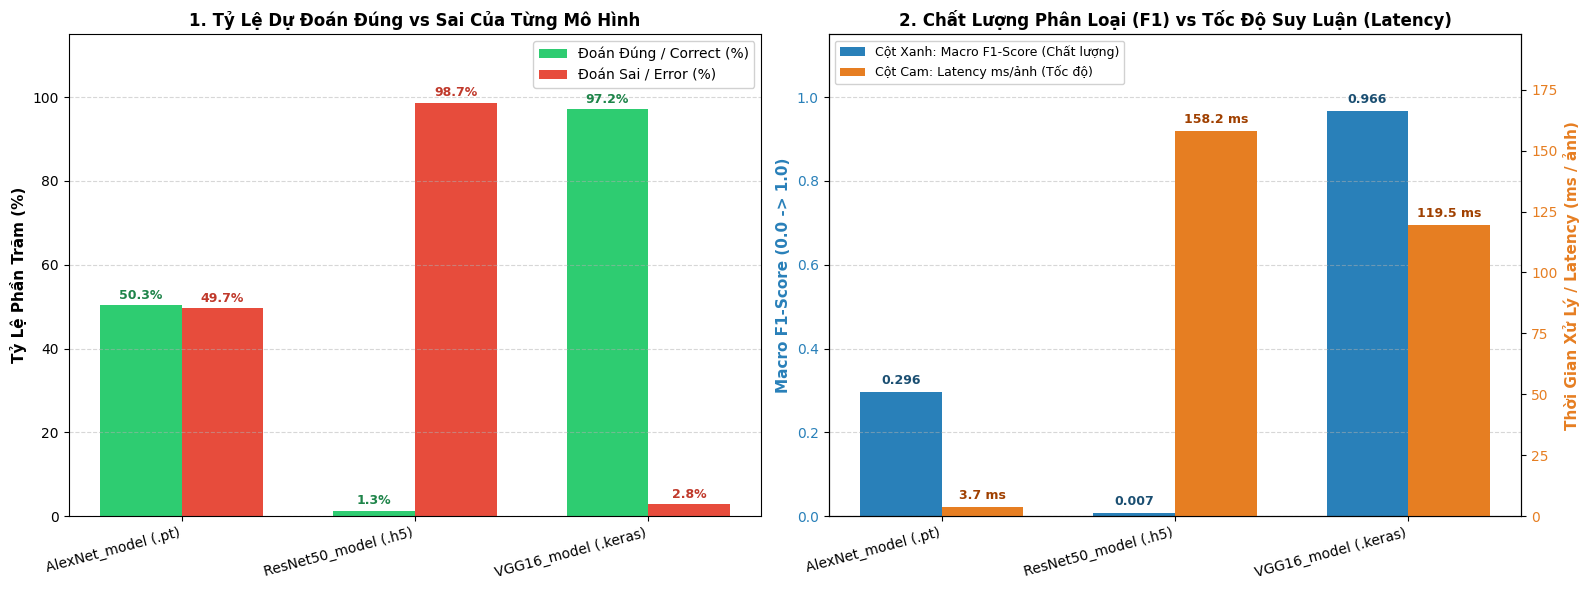

In [20]:
# Tự động nạp hàm vẽ mới nhất có chú thích đầy đủ
import importlib, sys
if "src.evaluation.model_comparator" in sys.modules:
    importlib.reload(sys.modules["src.evaluation.model_comparator"])
from src.evaluation.model_comparator import plot_model_comparison_charts

chart_fig = plot_model_comparison_charts(
    comparison_df=comparison_df,
    figsize=(16, 6),
    save_path=str(PROJECT_ROOT / "outputs/vgg16/plots/cross_model_benchmark_comparison.png"),
)
plt.show()


## 6. Trực Quan Hóa Chẩn Đoán 9 Ảnh (3x3 Grid) & Thống Kê Đúng / Sai

Yêu cầu trọng tâm: **"Hiện 9 ảnh và cho biết cái nào dự đoán đúng, dự đoán sai bao nhiêu phần trăm"**.

Hàm `visualize_9_predictions` hỗ trợ 4 chế độ lựa chọn 9 ảnh:
1. `mode='misclassified'`: Ưu tiên lọc 9 ảnh mà có ít nhất một mô hình dự đoán sai (nhằm phát hiện điểm yếu của mô hình).
2. `mode='disagreement'`: Lọc 9 ảnh mà các mô hình đưa ra dự đoán trái ngược nhau.
3. `mode='random'`: Lấy ngẫu nhiên 9 ảnh từ tập test.
4. `mode='correct'`: 9 ảnh mà các mô hình đều nhận diện chính xác.

Mỗi ảnh hiển thị viền màu sắc (Xanh lá nếu hoàn toàn đúng, Đỏ nếu có mô hình sai), kèm theo nhãn chuẩn (Ground Truth), nhãn dự đoán của từng mô hình cùng xác suất tin cậy (Confidence %).
Đồng thời, phần tiêu đề biểu đồ thống kê rõ: **`Model X: Đúng A/9 (A/9*100%) | Sai B/9 (B/9*100%)`**.


Đang trích xuất và hiển thị 9 ảnh kiểm thử (Chế độ: MISCLASSIFIED)...


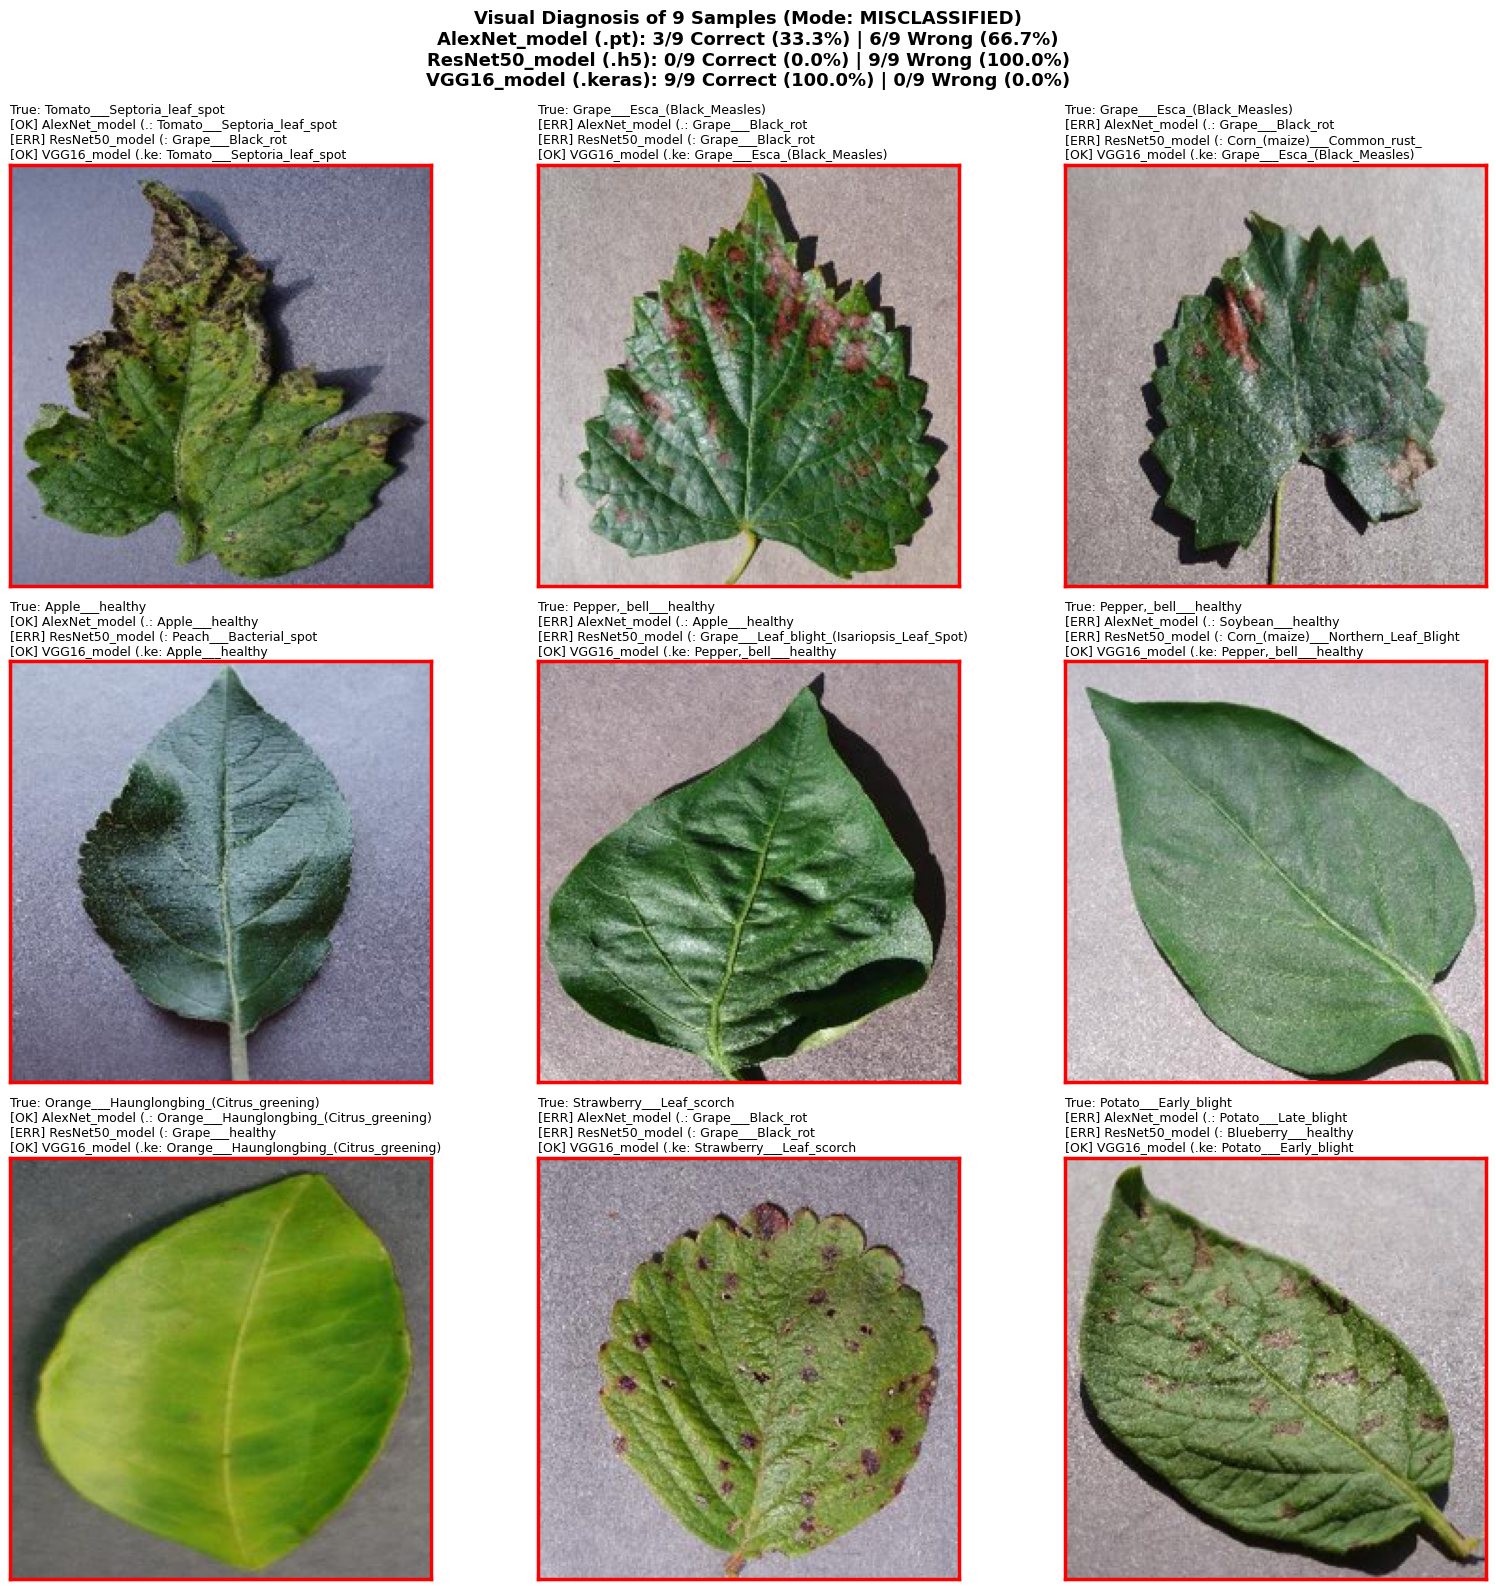

In [21]:
# Trường hợp A: Khảo sát 9 ảnh tập trung vào các trường hợp dự đoán sai / khó nhận diện
print('Đang trích xuất và hiển thị 9 ảnh kiểm thử (Chế độ: MISCLASSIFIED)...')
fig_9_err = visualize_9_predictions(
    models=loaded_models,
    images=test_images,
    labels=test_labels,
    class_names=class_names,
    eval_results=eval_results,
    mode='misclassified',
    random_seed=42,
    figsize=(16, 16),
    save_path=str(PROJECT_ROOT / 'outputs/vgg16/plots/diagnosis_9_samples_misclassified.png'),
)
plt.show()


Đang trích xuất và hiển thị 9 ảnh kiểm thử (Chế độ: RANDOM)...


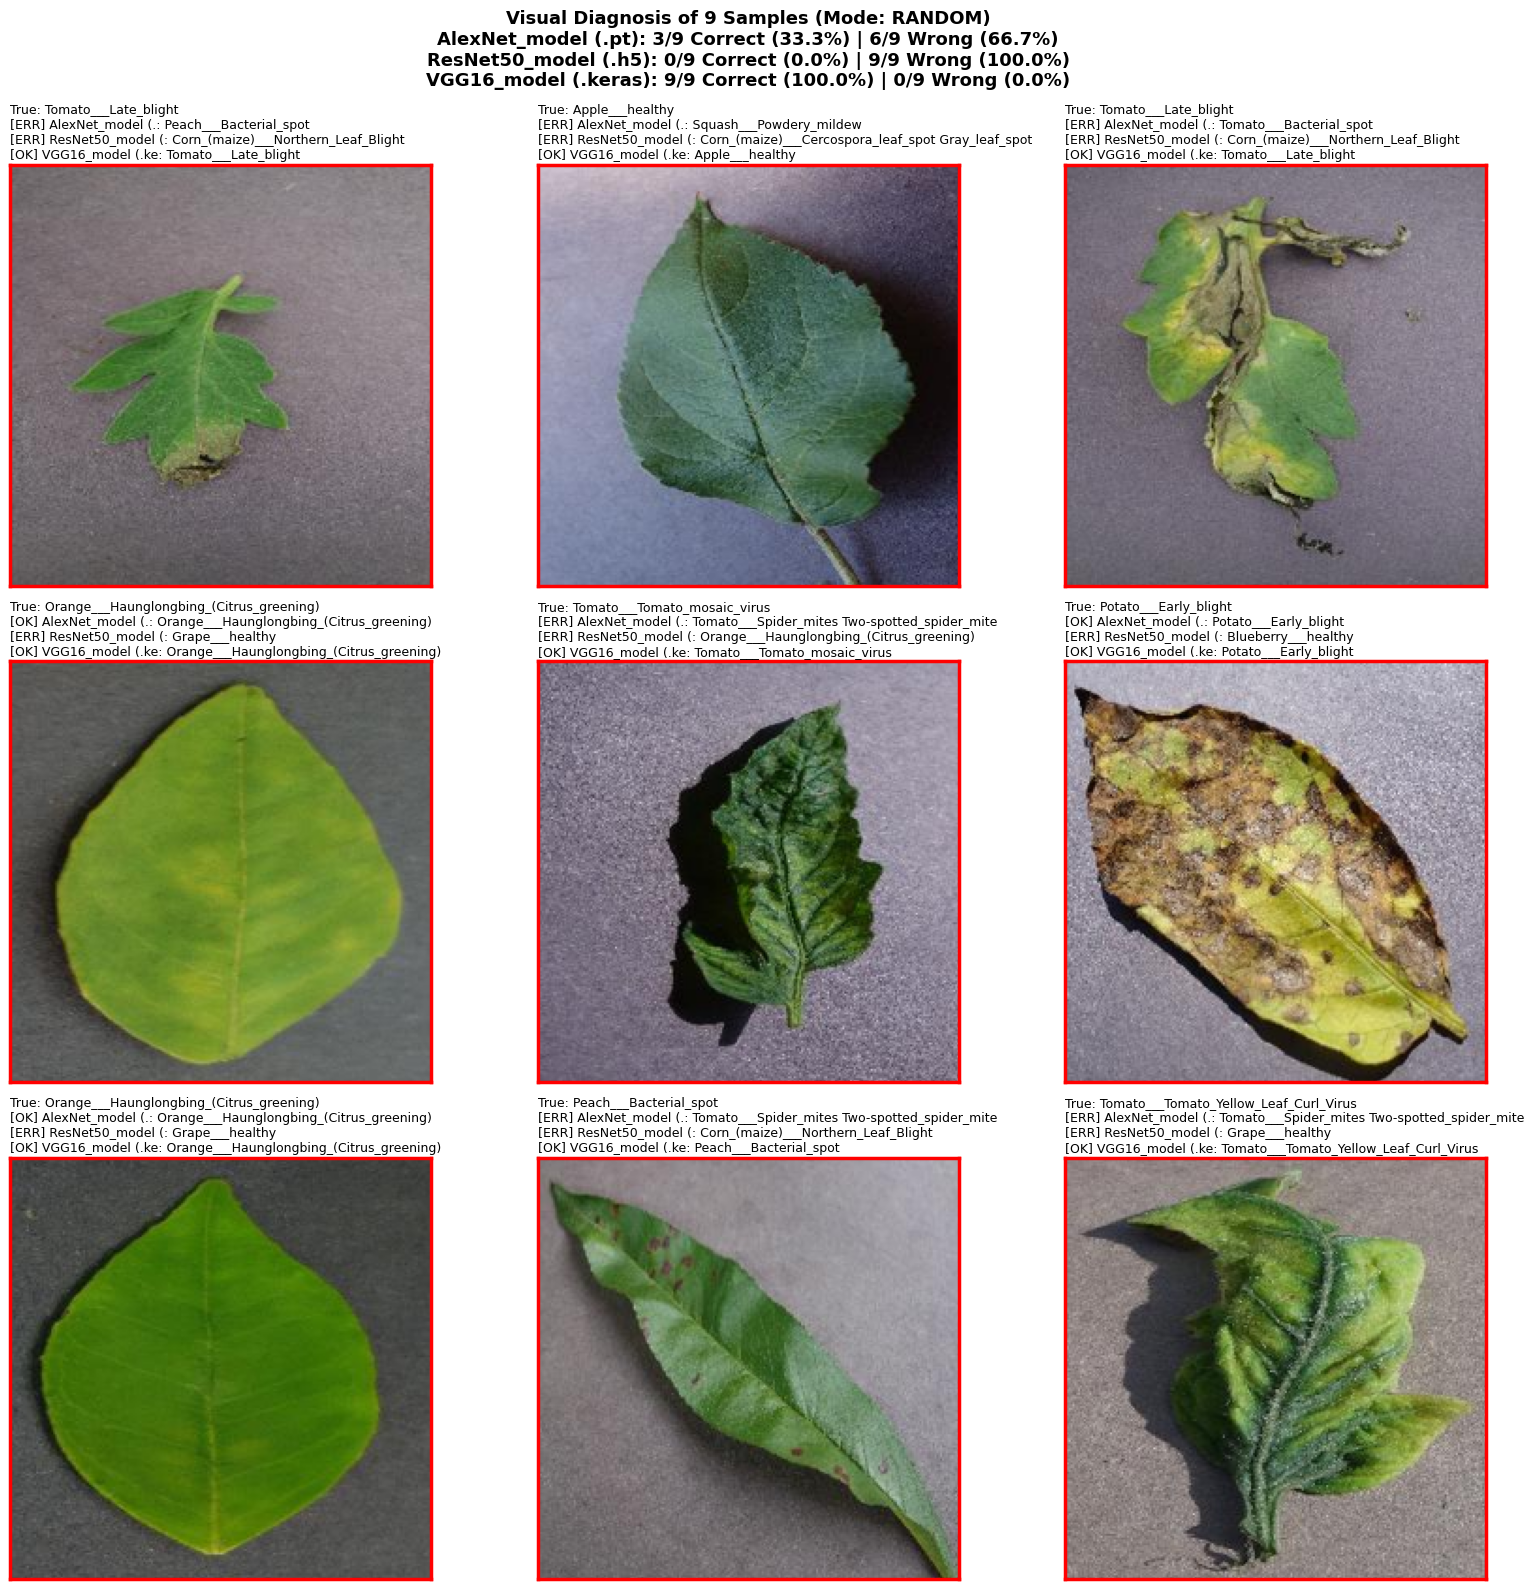

In [22]:
# Trường hợp B: Khảo sát 9 ảnh ngẫu nhiên đại diện trong tập kiểm thử
print('Đang trích xuất và hiển thị 9 ảnh kiểm thử (Chế độ: RANDOM)...')
fig_9_rand = visualize_9_predictions(
    models=loaded_models,
    images=test_images,
    labels=test_labels,
    class_names=class_names,
    eval_results=eval_results,
    mode='random',
    random_seed=101,
    figsize=(16, 16),
    save_path=str(PROJECT_ROOT / 'outputs/vgg16/plots/diagnosis_9_samples_random.png'),
)
plt.show()


## 7. Phân Tích Chi Tiết Các Lớp Nhận Diện Sai Nhiều Nhất (Error Breakdown)

Thống kê các lớp có tỷ lệ lỗi cao nhất của mô hình tốt nhất nhằm cung cấp thông tin hữu ích cho việc cải tiến kiến trúc hoặc bổ sung dữ liệu huấn luyện.


In [23]:
best_model_name = comparison_df.sort_values(by='Correct (%)', ascending=False).iloc[0]['Model']
best_res = eval_results[best_model_name]

# Tính tỷ lệ sai theo từng lớp
from collections import defaultdict
class_total = defaultdict(int)
class_wrong = defaultdict(int)

for true_lbl, pred_lbl in zip(test_labels, best_res['predictions']):
    class_total[true_lbl] += 1
    if true_lbl != pred_lbl:
        class_wrong[true_lbl] += 1

error_report_rows = []
for c_idx in class_total:
    tot = class_total[c_idx]
    wrg = class_wrong[c_idx]
    corr = tot - wrg
    error_report_rows.append({
        'Class Index': c_idx,
        'Class Name': class_names[c_idx],
        'Total Samples': tot,
        'Correct': corr,
        'Wrong': wrg,
        'Error Rate (%)': f"{(wrg / tot) * 100.0:.1f}%",
        'Accuracy (%)': f"{(corr / tot) * 100.0:.1f}%",
    })

error_df = pd.DataFrame(error_report_rows).sort_values(by='Wrong', ascending=False)
print(f"TOP CÁC LỚP BỊ NHẦM LẪN NHIỀU NHẤT TRÊN MÔ HÌNH: {best_model_name}")
display(error_df.head(10).style.set_properties(**{'text-align': 'left'}))


TOP CÁC LỚP BỊ NHẦM LẪN NHIỀU NHẤT TRÊN MÔ HÌNH: VGG16_model (.keras)


,Class Index,Class Name,Total Samples,Correct,Wrong,Error Rate (%),Accuracy (%)
12,29,Tomato___Early_blight,150,105,45,30.0%,70.0%
14,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,804,770,34,4.2%,95.8%
7,37,Tomato___healthy,238,220,18,7.6%,92.4%
17,30,Tomato___Late_blight,285,269,16,5.6%,94.4%
3,33,Tomato___Spider_mites Two-spotted_spider_mite,251,237,14,5.6%,94.4%
26,31,Tomato___Leaf_Mold,143,129,14,9.8%,90.2%
32,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,77,66,11,14.3%,85.7%
21,32,Tomato___Septoria_leaf_spot,265,254,11,4.2%,95.8%
16,28,Tomato___Bacterial_spot,319,310,9,2.8%,97.2%
0,34,Tomato___Target_Spot,211,204,7,3.3%,96.7%


## 8. Chẩn Đoán Ảnh Đơn Lẻ Tùy Chọn Từ Đường Dẫn (Single Image Diagnostic)

Cho phép người dùng chỉ định đường dẫn của một file ảnh lá cây bất kỳ trên máy và hiển thị phân tích xác suất Top-5 của các mô hình đã nạp.


Ảnh chẩn đoán: d:\2026-2027\computer-vision\plantvillage_dataset/color/Tomato___Target_Spot\cb9cc814-3103-4db1-9546-9efe49062625___Com.G_TgS_FL 9996.JPG
Nhãn thực tế  : Tomato___Target_Spot


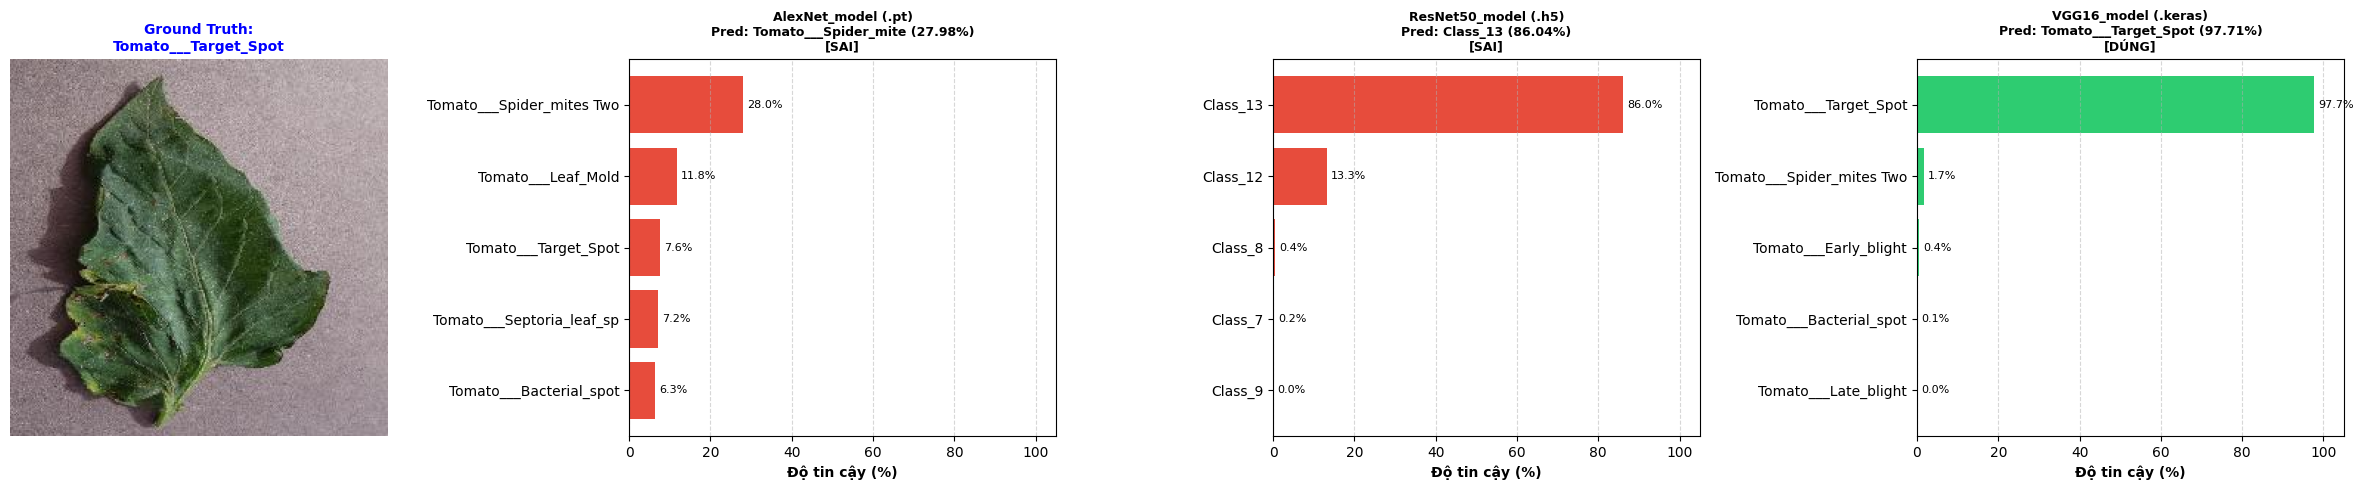

In [24]:
# Chọn một ảnh ngẫu nhiên từ tập test hoặc đường dẫn file tùy ý
sample_row = sample_test_df.iloc[0]
custom_image_path = str(sample_row['path'])
true_label_name = str(sample_row['class'])

print(f'Ảnh chẩn đoán: {custom_image_path}')
print(f'Nhãn thực tế  : {true_label_name}')

# Dự đoán bằng tất cả các mô hình
fig, axes = plt.subplots(1, len(loaded_models) + 1, figsize=(6 * (len(loaded_models) + 1), 5))

# Hiển thị ảnh lá cây
raw_img = Image.open(custom_image_path).convert('RGB')
axes[0].imshow(raw_img)
axes[0].set_title(f'Ground Truth:\n{true_label_name}', fontsize=10, fontweight='bold', color='blue')
axes[0].axis('off')

# Hiển thị biểu đồ Top-5 xác suất của từng mô hình
for idx, m in enumerate(loaded_models):
    ax = axes[idx + 1]
    pred_info = m.predict_single_image(custom_image_path, top_k=5)
    top_preds = pred_info['top_predictions']
    
    names = [p['class_name'][:25] for p in reversed(top_preds)]
    confs = [p['confidence'] * 100.0 for p in reversed(top_preds)]
    
    is_correct = (pred_info['predicted_class_name'] == true_label_name)
    bar_color = '#2ecc71' if is_correct else '#e74c3c'
    
    bars = ax.barh(names, confs, color=bar_color)
    ax.set_xlim(0, 105)
    ax.set_xlabel('Độ tin cậy (%)', fontweight='bold')
    ax.set_title(f"{m.name}\nPred: {pred_info['predicted_class_name'][:20]} ({pred_info['top_confidence_pct']})\n[{'DÚNG' if is_correct else 'SAI'}]", fontsize=9, fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8)

plt.tight_layout()
plt.show()


In [25]:
# ==============================================================================
# MỤC MỚI: KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ MCNEMAR GIỮA CÁC MÔ HÌNH
# ==============================================================================
from scipy.stats import binomtest
import itertools

print("Đang tiến hành kiểm định ý nghĩa thống kê McNemar giữa các cặp mô hình...")

model_names = list(eval_results.keys())
mcnemar_rows = []

# Duyệt qua từng cặp mô hình (A, B)
for a, b in itertools.combinations(model_names, 2):
    corr_a = eval_results[a]["is_correct"]
    corr_b = eval_results[b]["is_correct"]
    
    # Đếm số ảnh chỉ duy nhất 1 bên dự đoán đúng
    only_a = int((corr_a & ~corr_b).sum())
    only_b = int((~corr_a & corr_b).sum())
    total_disagreed = only_a + only_b
    
    # Kiểm định nhị thức 2 phía
    if total_disagreed > 0:
        p_val = binomtest(min(only_a, only_b), total_disagreed, 0.5).pvalue
    else:
        p_val = 1.0
        
    ket_luan = "Khác biệt có ý nghĩa (p < 0.05)" if p_val < 0.05 else "Chưa đủ bằng chứng khác nhau"
    
    mcnemar_rows.append({
        "Mô hình A": a,
        "Mô hình B": b,
        "Chỉ A đúng": only_a,
        "Chỉ B đúng": only_b,
        "p-value": round(p_val, 6),
        "Kết luận thống kê": ket_luan
    })

mcnemar_df = pd.DataFrame(mcnemar_rows)
print("\nBẢNG KẾT QUẢ KIỂM ĐỊNH MCNEMAR:")
display(mcnemar_df.style.set_properties(**{"text-align": "center"}))

Đang tiến hành kiểm định ý nghĩa thống kê McNemar giữa các cặp mô hình...

BẢNG KẾT QUẢ KIỂM ĐỊNH MCNEMAR:


,Mô hình A,Mô hình B,Chỉ A đúng,Chỉ B đúng,p-value,Kết luận thống kê
0,AlexNet_model (.pt),ResNet50_model (.h5),4060,69,0.000000,Khác biệt có ý nghĩa (p < 0.05)
1,AlexNet_model (.pt),VGG16_model (.keras),47,3860,0.000000,Khác biệt có ý nghĩa (p < 0.05)
2,ResNet50_model (.h5),VGG16_model (.keras),2,7806,0.000000,Khác biệt có ý nghĩa (p < 0.05)


In [26]:
# ==============================================================================
# MỤC MỚI: BẢNG XẾP HẠNG ĐA TIÊU CHÍ (RANKING MATRIX)
# ==============================================================================
# Trích xuất dữ liệu số từ bảng so sánh comparison_df
rank_data = []
for name in eval_results:
    res = eval_results[name]
    rank_data.append({
        "Mô hình": name,
        "Accuracy (%)": res["accuracy"] * 100.0,
        "Macro F1": res["macro_f1"],
        "Latency (ms)": res["latency_ms_per_sample"],
        "Params (M)": res["param_count"] / 1e6,
        "Dung lượng (MB)": res["file_size_mb"]
    })

rank_df = pd.DataFrame(rank_data).set_index("Mô hình")

# Định nghĩa tiêu chí: Càng cao càng tốt vs Càng thấp càng tốt
cang_cao_cang_tot = ["Accuracy (%)", "Macro F1"]
cang_thap_cang_tot = ["Latency (ms)", "Params (M)", "Dung lượng (MB)"]

ranking_table = pd.DataFrame(index=rank_df.index)
for col in cang_cao_cang_tot:
    ranking_table[col] = rank_df[col].rank(ascending=False, method="min").astype(int)
for col in cang_thap_cang_tot:
    ranking_table[col] = rank_df[col].rank(ascending=True, method="min").astype(int)

# Tính hạng trung bình (Điểm càng thấp càng toàn diện)
ranking_table["Hạng trung bình"] = ranking_table.mean(axis=1).round(2)
ranking_table = ranking_table.sort_values("Hạng trung bình")

print("BẢNG XẾP HẠNG CÁC MÔ HÌNH (Hạng 1 = Tốt nhất):")
display(ranking_table.style.highlight_min(color="#c8e6c9", axis=0))

BẢNG XẾP HẠNG CÁC MÔ HÌNH (Hạng 1 = Tốt nhất):


,Accuracy (%),Macro F1,Latency (ms),Params (M),Dung lượng (MB),Hạng trung bình
Mô hình,,,,,,
VGG16_model (.keras),1,1,2,1,2,1.400000
AlexNet_model (.pt),2,2,1,3,3,2.200000
ResNet50_model (.h5),3,3,3,2,1,2.400000


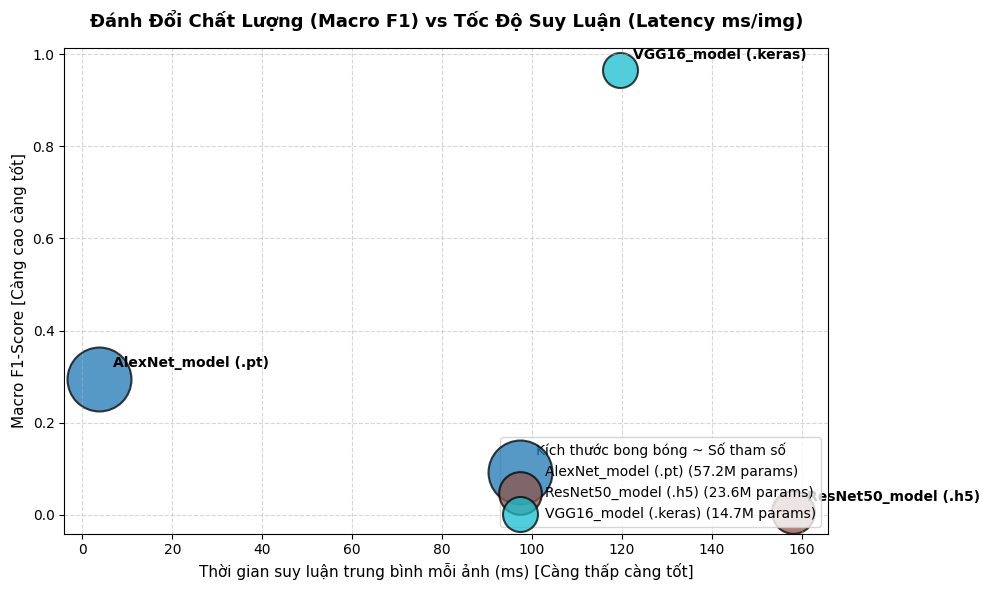

In [27]:
# ==============================================================================
# MỤC MỚI: BIỂU ĐỒ PHÂN TÁN ĐÁNH ĐỔI ĐỘ CHÍNH XÁC - TỐC ĐỘ (PARETO SCATTER)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(rank_df)))

for i, (m_name, row) in enumerate(rank_df.iterrows()):
    x = row["Latency (ms)"]
    y = row["Macro F1"]
    param_size = row["Params (M)"]
    
    # Điểm tròn có kích thước tỷ lệ thuận với số lượng tham số
    scatter = ax.scatter(
        x, y, 
        s=120 + 35 * param_size, 
        color=colors[i], 
        alpha=0.75, 
        edgecolor="black", 
        linewidth=1.5,
        label=f"{m_name} ({param_size:.1f}M params)"
    )
    
    # Gắn nhãn tên mô hình ngay cạnh điểm tròn
    ax.annotate(
        m_name, 
        (x, y), 
        textcoords="offset points", 
        xytext=(10, 8), 
        fontsize=10, 
        fontweight="bold"
    )

ax.set_title("Đánh Đổi Chất Lượng (Macro F1) vs Tốc Độ Suy Luận (Latency ms/img)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Thời gian suy luận trung bình mỗi ảnh (ms) [Càng thấp càng tốt]", fontsize=11)
ax.set_ylabel("Macro F1-Score [Càng cao càng tốt]", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)

# Đặt chú thích góc
ax.legend(title="Kích thước bong bóng ~ Số tham số", loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

TOP 10 LỚP BỆNH CÓ ĐỘ CHÊNH LỆCH F1 LỚN NHẤT GIỮA CÁC MÔ HÌNH:


,AlexNet_model (.pt),ResNet50_model (.h5),VGG16_model (.keras),Chênh_Lệch_F1
Raspberry___healthy,0.000,0.000,1.000,1.000
Corn_(maize)___healthy,0.986,0.000,1.000,1.000
Orange___Haunglongbing_(Citrus_greening),0.787,0.000,0.999,0.999
Soybean___healthy,0.813,0.000,0.997,0.997
Corn_(maize)___Common_rust_,0.954,0.000,0.997,0.997
Strawberry___Leaf_scorch,0.205,0.000,0.997,0.997
Squash___Powdery_mildew,0.762,0.000,0.996,0.996
"Pepper,_bell___healthy",0.036,0.000,0.995,0.995
Grape___Leaf_blight_(Isariopsis_Leaf_Spot),0.025,0.006,1.000,0.994
"Pepper,_bell___Bacterial_spot",0.013,0.000,0.993,0.993


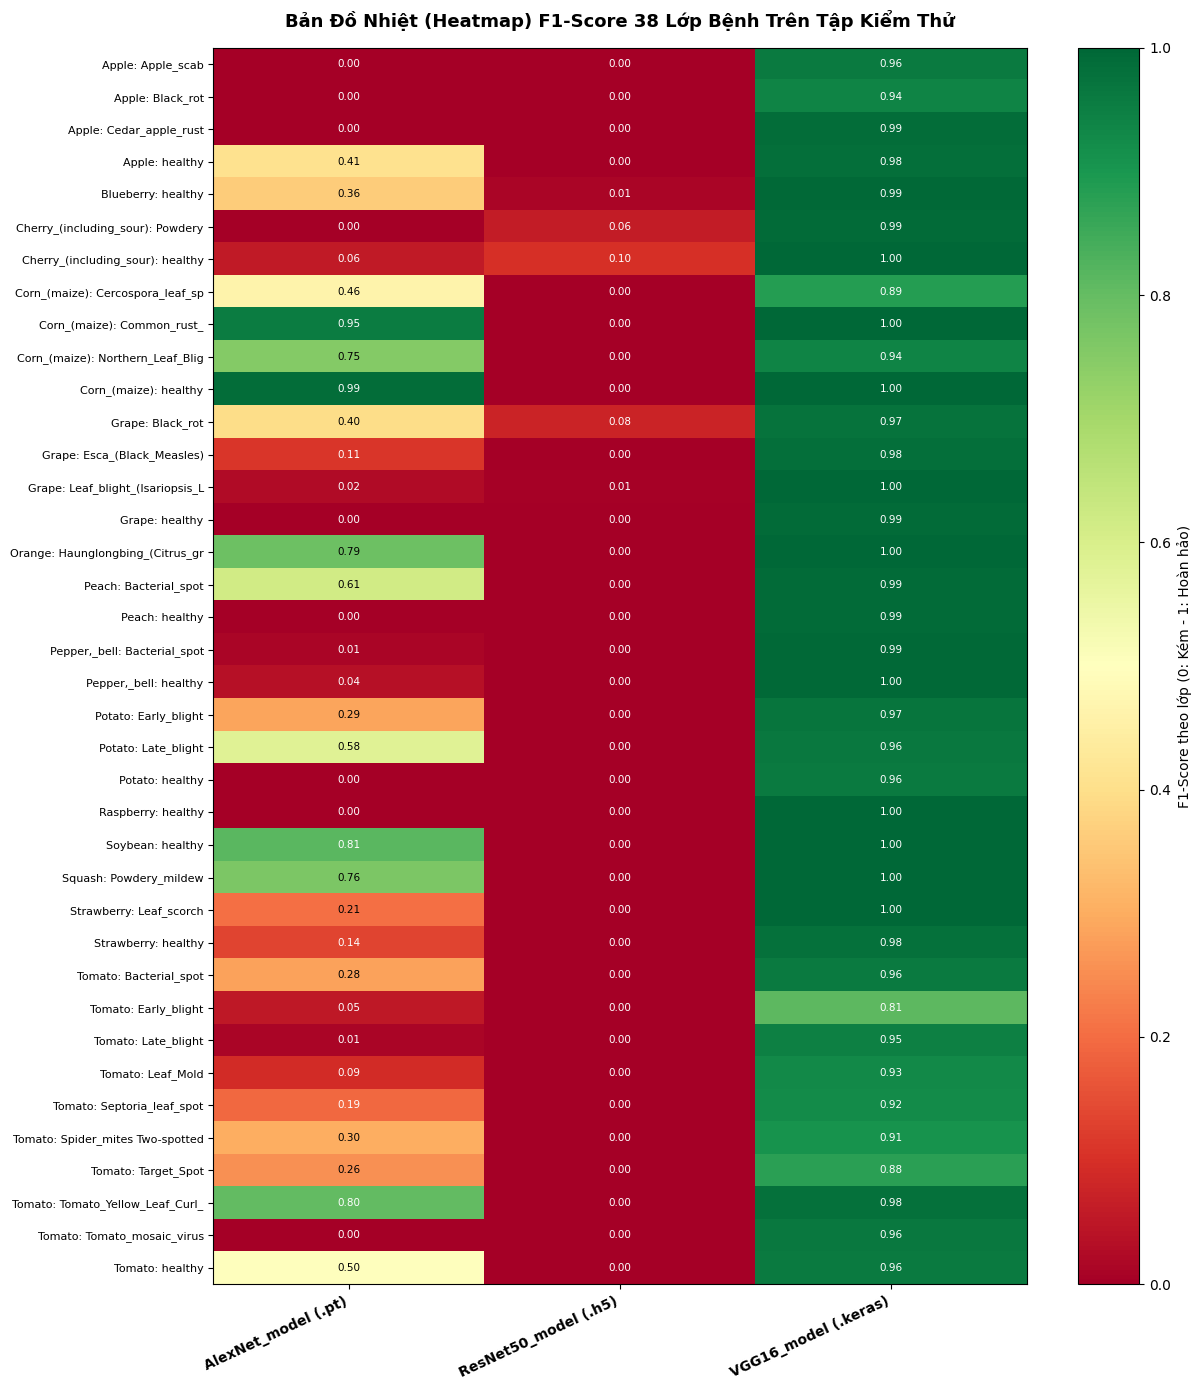

In [28]:
# ==============================================================================
# MỤC MỚI: PHÂN TÍCH F1 TỪNG LỚP & HEATMAP SO SÁNH 38 LỚP
# ==============================================================================
from sklearn.metrics import f1_score

# Tính F1-score riêng từng lớp cho từng mô hình
f1_per_class_dict = {}
for name in eval_results:
    preds = eval_results[name]["predictions"]
    f1_cls = f1_score(
        test_labels, 
        preds, 
        labels=range(len(class_names)), 
        average=None, 
        zero_division=0
    )
    f1_per_class_dict[name] = f1_cls

f1_class_df = pd.DataFrame(f1_per_class_dict, index=class_names)

# 1. Bảng Top 10 lớp các mô hình chênh lệch lớn nhất (Spread)
spread_values = (f1_class_df.max(axis=1) - f1_class_df.min(axis=1)).sort_values(ascending=False)
top10_spread = f1_class_df.loc[spread_values.index[:10]].assign(Chênh_Lệch_F1=spread_values.iloc[:10]).round(3)

print("TOP 10 LỚP BỆNH CÓ ĐỘ CHÊNH LỆCH F1 LỚN NHẤT GIỮA CÁC MÔ HÌNH:")
display(top10_spread)

# 2. Vẽ Heatmap F1 của cả 38 lớp
short_class_names = [c.replace("___", ": ")[:32] for c in class_names]
fig, ax = plt.subplots(figsize=(8 + len(eval_results) * 1.5, 14))

im = ax.imshow(
    f1_class_df.values, 
    cmap="RdYlGn", 
    vmin=max(0, np.nanmin(f1_class_df.values)), 
    vmax=1.0, 
    aspect="auto"
)

ax.set_xticks(range(len(eval_results)))
ax.set_xticklabels(list(eval_results.keys()), rotation=25, ha="right", fontsize=10, fontweight="bold")
ax.set_yticks(range(len(class_names)))
ax.set_yticklabels(short_class_names, fontsize=8)

for i in range(f1_class_df.shape[0]):
    for j in range(f1_class_df.shape[1]):
        val = f1_class_df.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.5, color="black" if 0.2 < val < 0.8 else "white")

plt.colorbar(im, label="F1-Score theo lớp (0: Kém - 1: Hoàn hảo)")
ax.set_title("Bản Đồ Nhiệt (Heatmap) F1-Score 38 Lớp Bệnh Trên Tập Kiểm Thử", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

In [29]:
# ==============================================================================
# MỤC MỚI: TỔNG KẾT NHANH CÁC MÔ HÌNH XUẤT SẮC NHẤT
# ==============================================================================
def find_leader(df, column, maximize=True):
    val = df[column].max() if maximize else df[column].min()
    m_name = df[column].idxmax() if maximize else df[column].idxmin()
    return m_name, val

print("="*65)
print("             TỔNG KẾT NHẬN ĐỊNH CÁC MÔ HÌNH ĐỐI CHUẨN")
print("="*65)

best_acc_model, best_acc = find_leader(rank_df, "Accuracy (%)", maximize=True)
print(f"[*] Độ chính xác cao nhất   : {best_acc_model:<25} ({best_acc:.2f}%)")

best_f1_model, best_f1 = find_leader(rank_df, "Macro F1", maximize=True)
print(f"[*] Macro F1 tốt nhất       : {best_f1_model:<25} ({best_f1:.4f})")

lightest_model, min_params = find_leader(rank_df, "Params (M)", maximize=False)
print(f"[*] Mô hình nhẹ nhất        : {lightest_model:<25} ({min_params:.2f} triệu tham số)")

fastest_model, min_lat = find_leader(rank_df, "Latency (ms)", maximize=False)
print(f"[*] Tốc độ suy luận nhanh nhất: {fastest_model:<25} ({min_lat:.2f} ms/ảnh)")

best_all_round = ranking_table.index[0]
print(f"[*] Mô hình toàn diện nhất  : {best_all_round:<25} (Hạng trung bình: {ranking_table.loc[best_all_round, 'Hạng trung bình']})")
print("="*65)

             TỔNG KẾT NHẬN ĐỊNH CÁC MÔ HÌNH ĐỐI CHUẨN
[*] Độ chính xác cao nhất   : VGG16_model (.keras)      (97.16%)
[*] Macro F1 tốt nhất       : VGG16_model (.keras)      (0.9661)
[*] Mô hình nhẹ nhất        : VGG16_model (.keras)      (14.73 triệu tham số)
[*] Tốc độ suy luận nhanh nhất: AlexNet_model (.pt)       (3.68 ms/ảnh)
[*] Mô hình toàn diện nhất  : VGG16_model (.keras)      (Hạng trung bình: 1.4)


#### Đánh giá trên tập dữ liệu dataset PlantDoc

In [30]:
# ==============================================================================
# CELL 27: KIỂM TRA & TỰ ĐỘNG CHUYỂN PLANTDOC VỀ ĐÚNG THƯ MỤC PROJECT GỐC
# ==============================================================================
import shutil
import zipfile
import urllib.request

# Sử dụng biến PROJECT_ROOT chuẩn đã có từ Cell 2
TARGET_DIR = PROJECT_ROOT / "plantvillage_dataset" / "plantdoc"

print(f"[*] Thư mục đích chuẩn: {TARGET_DIR}")

# 2. Kiểm tra dữ liệu tại thư mục đích chuẩn
image_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".PNG"}
valid_images = [f for f in TARGET_DIR.rglob("*") if f.suffix in image_extensions] if TARGET_DIR.exists() else []

if len(valid_images) > 0:
    subfolders = [d.name for d in TARGET_DIR.iterdir() if d.is_dir()]
    print("\n" + "="*65)
    print(" [THÀNH CÔNG] Dataset PlantDoc ĐÃ CÓ ở đúng vị trí:")
    print(f" -> Đường dẫn: {TARGET_DIR}")
    print(f" -> Tổng số ảnh: {len(valid_images):,} ảnh")
    print(f" -> Thư mục con: {subfolders}")
    print("="*65)
else:
    # 3. Chỉ tải mới nếu cả 2 nơi đều chưa có
    print("\n[-] Chưa có dữ liệu. Đang tải tệp ZIP từ GitHub...")
    ZIP_TEMP_PATH = PROJECT_ROOT / "plantvillage_dataset" / "plantdoc_temp.zip"
    DATASET_URL = "https://github.com/pratikkayal/PlantDoc-Dataset/archive/refs/heads/master.zip"

    def show_progress(b, b_size, total):
        sys.stdout.write(f"\r-> Đang tải: {b * b_size / (1024*1024):.1f} MB...")
        sys.stdout.flush()

    os.makedirs(TARGET_DIR.parent, exist_ok=True)
    urllib.request.urlretrieve(DATASET_URL, ZIP_TEMP_PATH, reporthook=show_progress)
    
    with zipfile.ZipFile(ZIP_TEMP_PATH, "r") as zip_ref:
        zip_ref.extractall(TARGET_DIR.parent)
        
    extracted = TARGET_DIR.parent / "PlantDoc-Dataset-master"
    if extracted.exists():
        if TARGET_DIR.exists():
            shutil.rmtree(TARGET_DIR)
        extracted.rename(TARGET_DIR)
        
    if ZIP_TEMP_PATH.exists():
        os.remove(ZIP_TEMP_PATH)
        
    valid_images = [f for f in TARGET_DIR.rglob("*") if f.suffix in image_extensions]
    print(f"\n[+] Tải xong {len(valid_images):,} ảnh vào: {TARGET_DIR}")

[*] Thư mục đích chuẩn: D:\2026-2027\computer-vision\plantvillage_dataset\plantdoc

 [THÀNH CÔNG] Dataset PlantDoc ĐÃ CÓ ở đúng vị trí:
 -> Đường dẫn: D:\2026-2027\computer-vision\plantvillage_dataset\plantdoc
 -> Tổng số ảnh: 2,573 ảnh
 -> Thư mục con: ['test', 'train']


In [31]:
# ==============================================================================
# CELL 28: ĐÁNH GIÁ TRÊN ẢNH THỰC ĐỊA NGOÀI ĐỒNG (PLANTDOC) - CHIA MINI-BATCH
# ==============================================================================
PLANTDOC_DIR = PROJECT_ROOT / "plantvillage_dataset" / "plantdoc" / "test"

# 1. Bảng ánh xạ 27 lớp thư mục PlantDoc -> Nhãn chuẩn PlantVillage
PLANTDOC_MAPPING = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}

if PLANTDOC_DIR.exists():
    print(f"[*] Đang nạp ảnh thực địa từ: {PLANTDOC_DIR}")
    
    pd_images, pd_labels = [], []
    valid_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".PNG"}
    matched_count = 0
    
    for doc_name, pv_name in PLANTDOC_MAPPING.items():
        doc_folder = PLANTDOC_DIR / doc_name
        if doc_folder.exists() and pv_name in class_names:
            cls_idx = class_names.index(pv_name)
            matched_count += 1
            for img_file in doc_folder.glob("*.*"):
                if img_file.suffix in valid_extensions:
                    try:
                        img = Image.open(img_file).convert("RGB").resize((224, 224))
                        pd_images.append(np.array(img, dtype=np.float32))
                        pd_labels.append(cls_idx)
                    except Exception:
                        continue
                        
    pd_images = np.array(pd_images)
    pd_labels = np.array(pd_labels)
    n_total = len(pd_images)
    print(f"[+] Đã nạp thành công: {matched_count}/27 lớp ({n_total} ảnh).")
    
    # 2. Đánh giá suy luận theo từng batch nhỏ (batch_size = 16) để chống tràn RAM/OOM
    print("\nĐang tiến hành đánh giá độ suy giảm hiệu năng ngoài thực địa...")
    plantdoc_res = []
    BATCH_SIZE = 32
    
    for wrapper in loaded_models:
        print(f" -> Đang chạy mô hình: {wrapper.name}...")
        all_preds = []
        
        # Chia nhỏ dữ liệu thành các cụm 16 ảnh
        for i in range(0, n_total, BATCH_SIZE):
            batch_chunk = pd_images[i : i + BATCH_SIZE]
            probs = wrapper.predict_proba(batch_chunk)
            all_preds.extend(np.argmax(probs, axis=1))
            
        preds = np.array(all_preds)
        acc_pd = (preds == pd_labels).mean() * 100.0
        
        # So sánh với Accuracy trên tập chuẩn PlantVillage
        acc_pv = eval_results[wrapper.name]["accuracy"] * 100.0
        suy_giam = acc_pv - acc_pd
        
        plantdoc_res.append({
            "Mô hình": wrapper.name,
            "Acc PlantVillage (%)": round(acc_pv, 2),
            "Acc Thực Địa PlantDoc (%)": round(acc_pd, 2),
            "Suy Giảm Hiệu Năng (% điểm)": round(suy_giam, 2),
        })
        
    print("\n" + "="*70)
    print(" BẢNG ĐÁNH GIÁ KHẢ NĂNG TỔNG QUÁT HÓA THỰC ĐỊA (GENERALIZATION)")
    print("="*70)
    display(pd.DataFrame(plantdoc_res).set_index("Mô hình").style.set_properties(**{"text-align": "center"}))
else:
    print(f"[-] Đường dẫn {PLANTDOC_DIR} chưa tồn tại.")

[*] Đang nạp ảnh thực địa từ: D:\2026-2027\computer-vision\plantvillage_dataset\plantdoc\test
[+] Đã nạp thành công: 27/27 lớp (236 ảnh).

Đang tiến hành đánh giá độ suy giảm hiệu năng ngoài thực địa...
 -> Đang chạy mô hình: AlexNet_model (.pt)...
 -> Đang chạy mô hình: ResNet50_model (.h5)...
 -> Đang chạy mô hình: VGG16_model (.keras)...

 BẢNG ĐÁNH GIÁ KHẢ NĂNG TỔNG QUÁT HÓA THỰC ĐỊA (GENERALIZATION)


,Acc PlantVillage (%),Acc Thực Địa PlantDoc (%),Suy Giảm Hiệu Năng (% điểm)
Mô hình,,,
AlexNet_model (.pt),50.340000,8.470000,41.860000
ResNet50_model (.h5),1.330000,2.120000,-0.790000
VGG16_model (.keras),97.160000,20.760000,76.400000
